In [2]:
!pip install langchain-groq


[notice] A new release of pip is available: 23.2.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from langchain_groq import ChatGroq

from __future__ import annotations

import operator
from typing import TypedDict, List, Annotated

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage

In [4]:
class Task(BaseModel):
    id:int
    title:str
    brief:str=Field(..., description="what to cover")

In [5]:
class Plan(BaseModel):
    blog_title:str
    tasks:List[Task]

In [6]:
class State(TypedDict):
    topic:str
    plan:Plan
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str
    

In [7]:
llm = ChatGroq(
    model="llama-3.1-8b-instant",
    temperature=0
)

In [16]:
def orchestrator(state:State)->dict:
    plan=llm.with_structured_output(Plan).invoke(
        [
                SystemMessage(
                content=(
                    "Create a blog plan with 5-7 sections on the following topic."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )
    return {"plan":plan}

In [10]:

def fanout(state: State):
    return [Send("worker", {"task": task, "topic": state["topic"], "plan": state["plan"]})
            for task in state["plan"].tasks]
    
#This function takes a plan with multiple tasks and creates one execution (Send) per task, so they can run in parallel on the worker node.
#Send("worker", {...}) means A command telling LangGraph: “Run this node (worker) with this input.”
    

In [11]:
def worker(payload:dict)->dict:
    #playload contains what we sent
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]
    blog_title=plan.blog_title
    
    section_md = llm.invoke(
        [
            SystemMessage(content="Write one clean Markdown section."),
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            ),
        ]
    ).content.strip()

    return {"sections": [section_md]}

In [12]:
from pathlib import Path
def reducer(state:State)->dict:
    title=state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()
    final_md = f"# {title}\n\n{body}\n"
    
     # ---- save to file ----
    filename = title.lower().replace(" ", "_") + ".md"
    output_path = Path(filename)
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}
    
    

In [19]:

g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

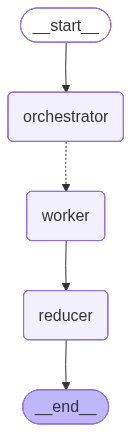

In [20]:

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"]) #“fanout is only allowed to send execution to the worker node.”
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [22]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})
out


{'topic': 'Write a blog on Self Attention',
 'plan': Plan(blog_title='Understanding Self Attention in Deep Learning', tasks=[Task(id=1, title='Introduction to Self Attention', brief='Define self attention and its importance in deep learning'), Task(id=2, title='How Self Attention Works', brief='Explain the mechanism of self attention and its components'), Task(id=3, title='Types of Self Attention', brief='Discuss the different types of self attention mechanisms'), Task(id=4, title='Applications of Self Attention', brief='Highlight the use cases of self attention in natural language processing and computer vision'), Task(id=5, title='Challenges and Limitations of Self Attention', brief='Discuss the challenges and limitations of self attention mechanisms'), Task(id=6, title='Future Directions of Self Attention', brief='Explore the potential future directions of self attention research'), Task(id=7, title='Conclusion', brief='Summarize the key points of self attention and its impact on de